# 02 · Does an SMS campaign increase purchases? An A/B analysis for a retail loyalty programme

**Business question.** A retailer sends an SMS to part of its loyalty-card holders. Does the SMS raise the probability that a customer buys, how big is the effect, for whom does it work, and is it worth the cost?

**Hypothesis.** H0: the SMS has no effect on the purchase rate. H1: it changes it (two-sided test, alpha = 0.05).

**Primary metric.** Purchase rate = share of customers with at least one purchase after the communication decision (`target`).
**Guardrails / limits.** The data has no spend, margin or unsubscribe information, so the economics in section 5 rely on explicit, editable assumptions.

**Data.** X5 Retail Group (Russian food retailer), *RetailHero uplift modelling* competition, 2019 ([source](https://ods.ai/competitions/x5-retailhero-uplift-modeling)). Customers were randomly flagged (`treatment_flg`) to receive an SMS; `target` records whether they purchased afterwards. The data is anonymised. No licence is stated by the source, so the files are **not** included in this repository: download `clients` and `uplift_train` from the source and place them in `data_raw/`.

**Scope.** Descriptive causal analysis of a randomised experiment: no machine learning. The aim is to show experiment design, validity checks, inference and a business recommendation.

> **Role of this notebook: analysis of results from an experiment run by someone else.**
> X5 Retail Group ran this SMS experiment in 2019 and published the data (RetailHero uplift competition).
> I did not run it; here I analyse the published results as I would analyse a test run by my own team.
> How I would design the *next* test is in `01_experiment_design.ipynb`; a refinement of this analysis
> with pre-experiment data (CUPED) is in `03_cuped_variance_reduction.ipynb`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep, proportion_confint
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from IPython.display import Markdown, display

# Chart style: neutral chrome, two categorical hues (treated = blue, control = orange)
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "figure.dpi": 110,
})
ALPHA = 0.05

## 1. Data and cleaning

Two tables: `clients` (loyalty-card holders) and `uplift_train` (one row per customer with the treatment flag and the outcome). `tenure_days` is measured to the latest card issue date in the file, which is a proxy for the snapshot date (the real campaign date is not given).

In [2]:
DATA = Path("..") / "data_raw"
for name in ("clients.csv.gz", "uplift_train.csv.gz"):
    if not (DATA / name).exists():
        raise FileNotFoundError(
            f"{DATA / name} not found. Download it from the Hugging Face dataset "
            "`pytorch-lifestream/retailhero-uplift` into the `data_raw/` folder (see README)."
        )
clients = pd.read_csv(DATA / "clients.csv.gz", parse_dates=["first_issue_date", "first_redeem_date"])
train = pd.read_csv(DATA / "uplift_train.csv.gz")
df = train.merge(clients, on="client_id", how="left", validate="1:1")

# Implausible ages (negative, > 100) are set to missing and kept in the analysis as "Unknown"
bad_age = ~df.age.between(16, 100)
df["age_clean"] = df.age.where(~bad_age)
df["age_group"] = pd.cut(df.age_clean, [15, 24, 34, 44, 54, 64, 100],
                         labels=["16-24", "25-34", "35-44", "45-54", "55-64", "65+"]).cat.add_categories("Unknown").fillna("Unknown").astype(str)
snapshot = clients.first_issue_date.max()
df["tenure_days"] = (snapshot - df.first_issue_date).dt.days
df["tenure_group"] = pd.qcut(df.tenure_days, 4, labels=["Q1 newest", "Q2", "Q3", "Q4 longest"]).astype(str)
df["has_redeemed"] = df.first_redeem_date.notna().astype(int)
# Guard: every randomised customer must belong to a segment (none may be dropped silently)
assert df[["age_group", "tenure_group"]].notna().all().all(), "Some customers have no age or tenure group"

print(f"Customers in experiment: {len(df):,}")
print(f"Duplicate client_id:     {df.client_id.duplicated().sum()}")
print(f"Missing target / flag:   {df[['target','treatment_flg']].isna().sum().sum()}")
print(f"Invalid ages set to NaN: {bad_age.sum():,} ({bad_age.mean():.2%})")
print(f"Gender unknown ('U'):    {(df.gender == 'U').mean():.1%}")
print(f"No first redeem date:    {(df.has_redeemed == 0).mean():.1%}")
df[["treatment_flg", "target", "age_clean", "tenure_days", "has_redeemed"]].describe().round(2)

Customers in experiment: 200,039
Duplicate client_id:     0
Missing target / flag:   0
Invalid ages set to NaN: 1,576 (0.79%)
Gender unknown ('U'):    46.4%
No first redeem date:    8.8%


,treatment_flg,target,age_clean,tenure_days,has_redeemed
count,200039.0,200039.00,198463.00,200039.00,200039.00
mean,0.5,0.62,46.53,430.21,0.91
std,0.5,0.49,15.79,203.65,0.28
min,0.0,0.00,16.00,0.00,0.00
25%,0.0,0.00,34.00,268.00,1.00
50%,0.0,1.00,45.00,485.00,1.00
75%,1.0,1.00,59.00,602.00,1.00
max,1.0,1.00,100.00,710.00,1.00


## 2. Is the experiment valid? Randomisation checks

An A/B result is only trustworthy if the groups were comparable before the treatment. Three checks:

1. **Sample ratio mismatch (SRM):** does the split match the intended allocation? The design ratio is not documented, so I assume 50/50 and check it.
2. **Covariate balance:** standardised mean differences (SMD) should be close to 0; a common rule of thumb is |SMD| < 0.1.
3. **Can covariates predict the assignment?** If randomisation worked, a model should do no better than a coin flip (AUC around 0.5).

`has_redeemed` is shown only as a diagnostic: the campaign date is unknown, so it could partly be measured after the treatment and is not used as a segmentation variable.

Control: 100,058  Treated: 99,981  (treated share 49.98%)
SRM chi-square test vs 50/50: chi2 = 0.03, p = 0.863
AUC of covariates predicting treatment: 0.501 (0.5 = no signal)


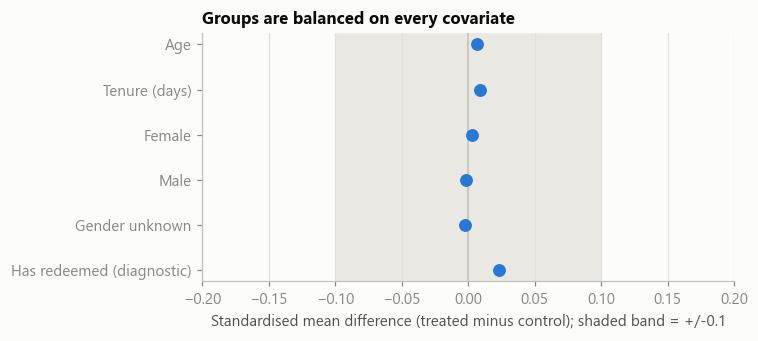

,SMD
Age,0.0064
Tenure (days),0.0086
Female,0.0032
Male,-0.0013
Gender unknown,-0.0021
Has redeemed (diagnostic),0.0234


In [3]:
n_c, n_t = (df.treatment_flg == 0).sum(), (df.treatment_flg == 1).sum()
chi2, p_srm = stats.chisquare([n_c, n_t])
print(f"Control: {n_c:,}  Treated: {n_t:,}  (treated share {n_t/len(df):.2%})")
print(f"SRM chi-square test vs 50/50: chi2 = {chi2:.2f}, p = {p_srm:.3f}")

cov = df.assign(female=(df.gender == "F").astype(int), male=(df.gender == "M").astype(int),
                gender_unknown=(df.gender == "U").astype(int))
cols = ["age_clean", "tenure_days", "female", "male", "gender_unknown", "has_redeemed"]
t, c = cov[cov.treatment_flg == 1], cov[cov.treatment_flg == 0]
smd = pd.Series({k: (t[k].mean() - c[k].mean()) / np.sqrt((t[k].var() + c[k].var()) / 2) for k in cols})
smd.index = ["Age", "Tenure (days)", "Female", "Male", "Gender unknown", "Has redeemed (diagnostic)"]

# Predictability of the assignment from covariates (5-fold AUC)
X = cov[["age_clean", "tenure_days", "female", "male", "has_redeemed"]].copy()
X["age_clean"] = X.age_clean.fillna(X.age_clean.median())
auc = cross_val_score(LogisticRegression(max_iter=1000), (X - X.mean()) / X.std(), cov.treatment_flg,
                      cv=5, scoring="roc_auc")
print(f"AUC of covariates predicting treatment: {auc.mean():.3f} (0.5 = no signal)")

balanced = (smd.abs() < 0.1).all()
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.axvspan(-0.1, 0.1, color=GRID, alpha=0.7, lw=0)
ax.axvline(0, color=AXIS, lw=1)
ax.scatter(smd.values, range(len(smd)), s=55, color=BLUE, zorder=3)
ax.set_yticks(range(len(smd))); ax.set_yticklabels(smd.index); ax.invert_yaxis()
ax.set_xlim(-0.2, 0.2); ax.set_xlabel("Standardised mean difference (treated minus control); shaded band = +/-0.1")
ax.grid(axis="y", visible=False)
ax.set_title("Groups are balanced on every covariate" if balanced else "Some covariates are imbalanced")
plt.tight_layout(); plt.show()
smd.round(4).to_frame("SMD")

## 3. Average effect of the SMS

Two-sided z-test for two proportions, with a 95% confidence interval for the absolute difference (percentage points) and for the relative lift (log-ratio interval).

Control purchase rate: 60.33%   Treated purchase rate: 63.65%
Absolute effect: +3.32 pp  (95% CI +2.90 to +3.75)
Relative lift:   +5.51%  (95% CI +4.79% to +6.24%)
z = 15.31, p = 6.62e-53


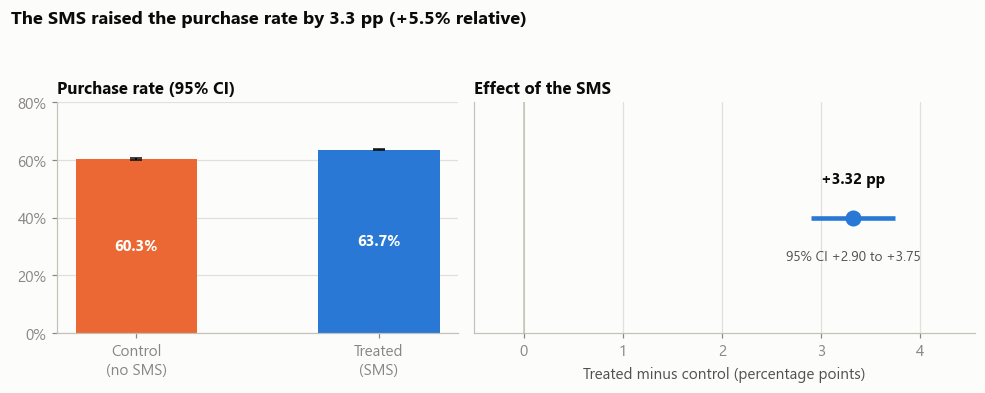

In [4]:
g = df.groupby("treatment_flg").target.agg(["sum", "count", "mean"])
xc, nc = int(g.loc[0, "sum"]), int(g.loc[0, "count"])
xt, nt = int(g.loc[1, "sum"]), int(g.loc[1, "count"])
pc, pt = xc / nc, xt / nt
diff = pt - pc
lo, hi = confint_proportions_2indep(xt, nt, xc, nc, method="wald", compare="diff")
rlo, rhi = confint_proportions_2indep(xt, nt, xc, nc, method="log", compare="ratio")
z, p_ate = proportions_ztest([xt, xc], [nt, nc])
rel = pt / pc - 1

print(f"Control purchase rate: {pc:.2%}   Treated purchase rate: {pt:.2%}")
print(f"Absolute effect: {diff*100:+.2f} pp  (95% CI {lo*100:+.2f} to {hi*100:+.2f})")
print(f"Relative lift:   {rel:+.2%}  (95% CI {rlo-1:+.2%} to {rhi-1:+.2%})")
print(f"z = {z:.2f}, p = {p_ate:.2e}")

ci_c = proportion_confint(xc, nc, method="normal"); ci_t = proportion_confint(xt, nt, method="normal")
fig, (a, b) = plt.subplots(1, 2, figsize=(9, 3.6), gridspec_kw={"width_ratios": [1, 1.25]})
vals = [pc, pt]; cis = [ci_c, ci_t]; cols_ = [ORANGE, BLUE]; names = ["Control\n(no SMS)", "Treated\n(SMS)"]
for i in range(2):
    a.bar(i, vals[i], width=0.5, color=cols_[i], zorder=2)
    a.errorbar(i, vals[i], yerr=[[vals[i] - cis[i][0]], [cis[i][1] - vals[i]]], color=INK, lw=1.3, capsize=4, zorder=3)
    a.text(i, vals[i] / 2, f"{vals[i]:.1%}", ha="center", va="center", color="white", fontweight="bold")
a.set_xticks([0, 1]); a.set_xticklabels(names); a.set_ylim(0, 0.8)
a.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}"); a.grid(axis="x", visible=False)
a.set_title("Purchase rate (95% CI)")
b.axvline(0, color=AXIS, lw=1)
b.hlines(0, lo * 100, hi * 100, color=BLUE, lw=3, zorder=2)
b.scatter([diff * 100], [0], s=90, color=BLUE, zorder=3)
b.text(diff * 100, 0.18, f"{diff*100:+.2f} pp", ha="center", fontweight="bold")
b.text(diff * 100, -0.22, f"95% CI {lo*100:+.2f} to {hi*100:+.2f}", ha="center", color=INK2, fontsize=9)
b.set_ylim(-0.6, 0.6); b.set_yticks([]); b.grid(axis="y", visible=False)
b.set_xlim(min(-0.5, lo * 100 - 0.5), hi * 100 + 0.8); b.set_xlabel("Treated minus control (percentage points)")
b.set_title("Effect of the SMS")
fig.suptitle(f"The SMS raised the purchase rate by {diff*100:.1f} pp ({rel:+.1%} relative)", x=0.01, ha="left",
             fontsize=12, fontweight="bold")
plt.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

### Power and sample size (the design question)

Before running a test like this one, the questions are: *how many customers per arm do we need to detect an effect of a given size?* and *what is the smallest effect this experiment could detect?* Both depend on the baseline rate and on the power we want (80%).

In [5]:
power = NormalIndPower()
rows = []
for d_pp in [0.5, 1.0, 2.0, 3.0]:
    h = proportion_effectsize(pc + d_pp / 100, pc)
    n_needed = power.solve_power(effect_size=h, alpha=ALPHA, power=0.8, ratio=1.0)
    rows.append({"effect to detect (pp)": d_pp, "customers per arm": int(np.ceil(n_needed))})
display(pd.DataFrame(rows).set_index("effect to detect (pp)"))

h_min = power.solve_power(nobs1=nc, alpha=ALPHA, power=0.8, ratio=nt / nc)
mde = np.sin(np.arcsin(np.sqrt(pc)) + h_min / 2) ** 2 - pc
print(f"With {nc:,} customers per arm and a {pc:.1%} baseline, the minimum detectable effect (80% power) is about {mde*100:.2f} pp.")

,customers per arm
effect to detect (pp),
0.5,149950
1.0,37403
2.0,9306
3.0,4115


With 100,058 customers per arm and a 60.3% baseline, the minimum detectable effect (80% power) is about 0.61 pp.


## 4. Who responds? Effects by segment

Segments (age, gender, tenure) are used to ask whether the effect differs across customers. Two safeguards against false discoveries:

- A **global heterogeneity test** per dimension (likelihood-ratio test of treatment x segment interaction in a logistic model).
- A **Benjamini-Hochberg correction** across all 14 segment-level tests, since testing many subgroups produces false positives by chance.

Segments are exploratory: they were not pre-registered.

In [6]:
def seg_table(col, order):
    rows = []
    for lvl in order:
        s = df[df[col] == lvl]
        t_, c_ = s[s.treatment_flg == 1].target, s[s.treatment_flg == 0].target
        xt_, nt_, xc_, nc_ = t_.sum(), len(t_), c_.sum(), len(c_)
        d_ = xt_ / nt_ - xc_ / nc_
        l_, h_ = confint_proportions_2indep(xt_, nt_, xc_, nc_, method="wald", compare="diff")
        _, p_ = proportions_ztest([xt_, xc_], [nt_, nc_])
        rows.append(dict(dimension=col, level=lvl, n=nt_ + nc_, rate_control=xc_ / nc_, rate_treated=xt_ / nt_,
                         diff_pp=d_ * 100, ci_low_pp=l_ * 100, ci_high_pp=h_ * 100, p_value=p_))
    return pd.DataFrame(rows)

dims = [("age_group", ["16-24", "25-34", "35-44", "45-54", "55-64", "65+", "Unknown"], "Age"),
        ("gender", ["F", "M", "U"], "Gender"),
        ("tenure_group", ["Q1 newest", "Q2", "Q3", "Q4 longest"], "Tenure")]
seg = pd.concat([seg_table(c, o) for c, o, _ in dims], ignore_index=True)
seg["p_adj_bh"] = multipletests(seg.p_value, method="fdr_bh")[1]
seg["significant"] = seg.p_adj_bh < ALPHA

def het_test(col):
    d = df.assign(seg=df[col].astype(str))
    red = smf.logit("target ~ treatment_flg + C(seg)", d).fit(disp=0)
    full = smf.logit("target ~ treatment_flg * C(seg)", d).fit(disp=0)
    lr = 2 * (full.llf - red.llf); dof = int(full.df_model - red.df_model)
    return lr, dof, stats.chi2.sf(lr, dof)

het = {name: het_test(c) for c, _, name in dims}
fmt_p = lambda p: "< 0.001" if p < 0.001 else f"= {p:.3f}"
for name, (lr, dof, p) in het.items():
    print(f"Heterogeneity across {name:<7}: LR chi2 = {lr:6.2f}, df = {dof}, p {fmt_p(p)}")

seg.round({"rate_control": 4, "rate_treated": 4, "diff_pp": 2, "ci_low_pp": 2, "ci_high_pp": 2,
           "p_value": 4, "p_adj_bh": 4}).drop(columns="dimension").set_index(seg.dimension.map({c: n for c, _, n in dims}) + " | " + seg.level)

Heterogeneity across Age    : LR chi2 =  49.05, df = 6, p < 0.001
Heterogeneity across Gender : LR chi2 =   7.63, df = 2, p = 0.022
Heterogeneity across Tenure : LR chi2 =  12.40, df = 3, p = 0.006


,level,n,rate_control,rate_treated,diff_pp,ci_low_pp,ci_high_pp,p_value,p_adj_bh,significant
Age | 16-24,16-24,15265,0.5835,0.5969,1.34,-0.22,2.90,0.0924,0.0995,False
Age | 25-34,25-34,38113,0.5852,0.6011,1.58,0.60,2.57,0.0016,0.0019,True
Age | 35-44,35-44,42458,0.5928,0.6233,3.06,2.13,3.99,0.0000,0.0000,True
Age | 45-54,45-54,34262,0.5967,0.6305,3.38,2.35,4.41,0.0000,0.0000,True
Age | 55-64,55-64,38610,0.6193,0.6593,4.01,3.05,4.96,0.0000,0.0000,True
Age | 65+,65+,29755,0.6426,0.7016,5.90,4.83,6.96,0.0000,0.0000,True
Age | Unknown,Unknown,1576,0.5271,0.5629,3.58,-1.34,8.50,0.1538,0.1538,False
Gender | F,F,73696,0.6204,0.6607,4.03,3.33,4.72,0.0000,0.0000,True
Gender | M,M,33511,0.6068,0.6361,2.93,1.89,3.97,0.0000,0.0000,True
Gender | U,U,92832,0.5884,0.6174,2.90,2.27,3.53,0.0000,0.0000,True


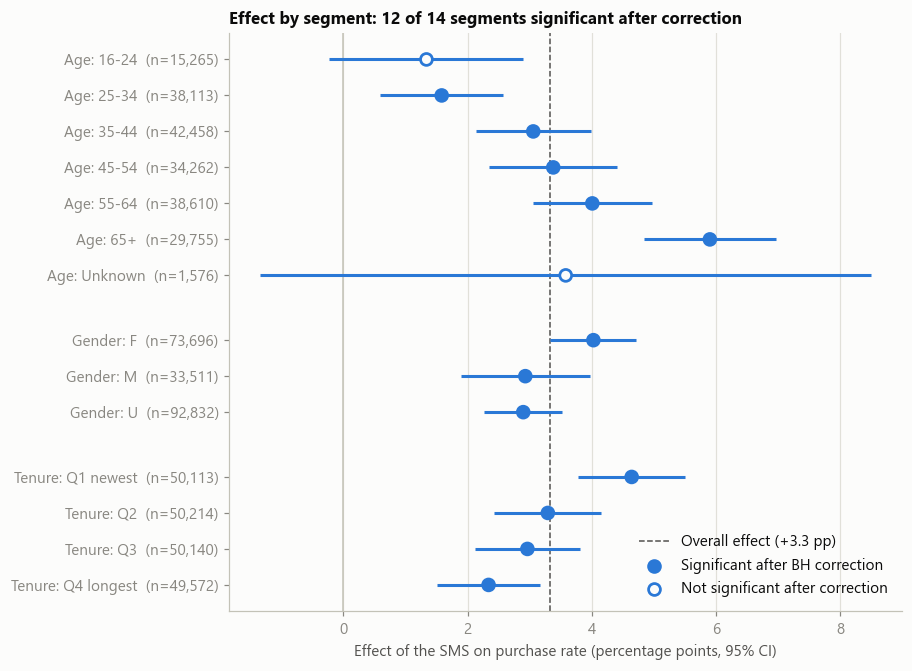

In [7]:
fig, ax = plt.subplots(figsize=(8.4, 6.2))
y, ys, labels = 0, [], []
names = {c: n for c, _, n in dims}
for c, _, _ in dims:
    for _, r in seg[seg.dimension == c].iterrows():
        ys.append(y); labels.append(f"{names[c]}: {r.level}  (n={r.n:,})"); y += 1
    y += 0.8
ys = np.array(ys)
ax.axvline(0, color=AXIS, lw=1)
ax.axvline(diff * 100, color=INK2, lw=1, ls="--")
ax.hlines(ys, seg.ci_low_pp, seg.ci_high_pp, color=BLUE, lw=2, zorder=2)
ax.scatter(seg.diff_pp, ys, s=60, zorder=3, edgecolor=BLUE, linewidth=1.8,
           facecolor=[BLUE if s else SURFACE for s in seg.significant])
ax.set_yticks(ys); ax.set_yticklabels(labels); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("Effect of the SMS on purchase rate (percentage points, 95% CI)")
ax.plot([], [], color=INK2, lw=1, ls="--", label=f"Overall effect ({diff*100:+.1f} pp)")
ax.scatter([], [], s=60, facecolor=BLUE, edgecolor=BLUE, linewidth=1.8, label="Significant after BH correction")
ax.scatter([], [], s=60, facecolor=SURFACE, edgecolor=BLUE, linewidth=1.8, label="Not significant after correction")
ax.legend(loc="lower right", frameon=False)
n_sig = int(seg.significant.sum())
ax.set_title(f"Effect by segment: {n_sig} of {len(seg)} segments significant after correction")
plt.tight_layout(); plt.show()

## 5. Is it worth sending? Break-even economics

The dataset has no revenue or cost fields, so the two inputs below are **hypothetical and editable**: change them with the retailer's real numbers.

- `COST_PER_SMS`: all-in cost of one message.
- `MARGIN_PER_INCREMENTAL_PURCHASE`: gross margin earned on a purchase that happened *because of* the SMS.

Net value per 1,000 SMS = 1,000 x (effect x margin per incremental purchase - cost per SMS). The key output is the **break-even margin**: the minimum value of an incremental purchase for which the campaign pays back.

Incremental purchases per 1,000 SMS: 33.2 (95% CI 29.0 to 37.5)
Net value per 1,000 SMS with the assumptions above: EUR 50


,"break-even margin, point estimate (EUR)","break-even margin, CI lower bound (EUR)"
cost per SMS (EUR),,
0.02,0.60,0.69
0.05,1.50,1.73
0.10,3.01,3.45


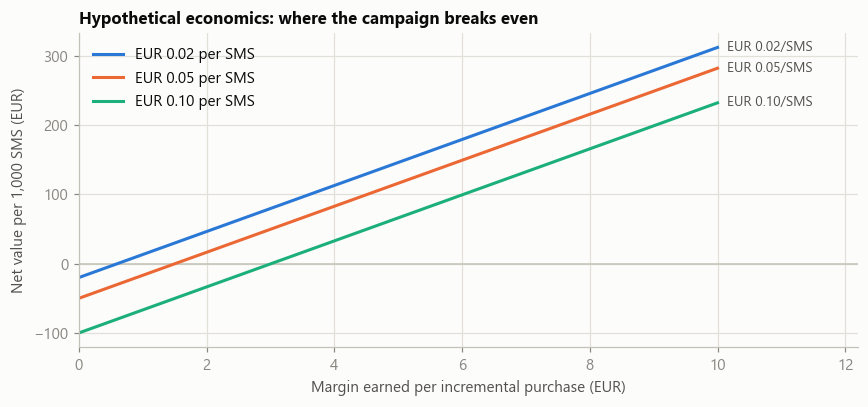

In [8]:
COST_PER_SMS = 0.05                      # EUR, assumption
MARGIN_PER_INCREMENTAL_PURCHASE = 3.00   # EUR, assumption

net_1000 = 1000 * (diff * MARGIN_PER_INCREMENTAL_PURCHASE - COST_PER_SMS)
print(f"Incremental purchases per 1,000 SMS: {diff*1000:.1f} (95% CI {lo*1000:.1f} to {hi*1000:.1f})")
print(f"Net value per 1,000 SMS with the assumptions above: EUR {net_1000:,.0f}")

costs = [0.02, 0.05, 0.10]
be = pd.DataFrame({"cost per SMS (EUR)": costs,
                   "break-even margin, point estimate (EUR)": [c / diff for c in costs],
                   "break-even margin, CI lower bound (EUR)": [c / lo if lo > 0 else np.nan for c in costs]}).round(2)
display(be.set_index("cost per SMS (EUR)"))

m = np.linspace(0, 10, 101)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.axhline(0, color=AXIS, lw=1)
for c_, col in zip(costs, [BLUE, ORANGE, AQUA]):
    v = 1000 * (diff * m - c_)
    ax.plot(m, v, color=col, lw=2, label=f"EUR {c_:.2f} per SMS")
    ax.text(10.15, v[-1], f"EUR {c_:.2f}/SMS", color=INK2, va="center", fontsize=9)
ax.set_xlim(0, 12.2); ax.set_xlabel("Margin earned per incremental purchase (EUR)")
ax.set_ylabel("Net value per 1,000 SMS (EUR)")
ax.legend(loc="upper left", frameon=False)
ax.set_title("Hypothetical economics: where the campaign breaks even")
plt.tight_layout(); plt.show()

## 6. Summary and recommendation

In [9]:
sig_pos = seg[seg.significant & (seg.diff_pp > 0)].sort_values("diff_pp", ascending=False)
het_txt = "; ".join(f"{k}: p {fmt_p(v[2])}" for k, v in het.items())
be_main = COST_PER_SMS / diff
age_known = seg[(seg.dimension == "age_group") & (seg.level != "Unknown")]
a_hi, a_lo = age_known.loc[age_known.diff_pp.idxmax()], age_known.loc[age_known.diff_pp.idxmin()]
ten = seg[seg.dimension == "tenure_group"]
t_hi, t_lo = ten.loc[ten.diff_pp.idxmax()], ten.loc[ten.diff_pp.idxmin()]
trend = "rises steadily with age" if age_known.diff_pp.is_monotonic_increasing else "varies with age"
be_hi, be_lo = COST_PER_SMS / (a_hi.diff_pp / 100), COST_PER_SMS / (a_lo.diff_pp / 100)
txt = f'''
**Result.** Customers who received the SMS bought at **{pt:.1%}** versus **{pc:.1%}** for control: an effect of **{diff*100:+.2f} pp** (95% CI {lo*100:+.2f} to {hi*100:+.2f}; relative lift {rel:+.1%}; p = {p_ate:.1e}). Randomisation checks pass: split {n_t/len(df):.2%} treated, SRM p = {p_srm:.2f}, all |SMD| < 0.1: {balanced}, assignment AUC {auc.mean():.3f}.

**Heterogeneity.** Global tests of treatment x segment interaction: {het_txt}. {n_sig} of {len(seg)} segment-level effects are significant after Benjamini-Hochberg correction.

**Who responds.** The effect {trend}: **{a_lo.diff_pp:+.1f} pp** for ages {a_lo.level} versus **{a_hi.diff_pp:+.1f} pp** for {a_hi.level}. By tenure it is largest for {t_hi.level} ({t_hi.diff_pp:+.1f} pp) and smallest for {t_lo.level} ({t_lo.diff_pp:+.1f} pp). Older customers also buy more at baseline, so these are absolute gains on different starting points.

**Economics (hypothetical inputs).** At EUR {COST_PER_SMS:.2f} per SMS the campaign breaks even if an incremental purchase is worth at least **EUR {be_main:.2f}** of margin overall (EUR {COST_PER_SMS/lo:.2f} using the pessimistic end of the interval). By segment the bar moves from EUR {be_hi:.2f} ({a_hi.level}) to EUR {be_lo:.2f} ({a_lo.level}).

**Recommendation.** The SMS has a real but modest effect on purchase probability. Roll it out only if the retailer's incremental purchase value exceeds the break-even above. Prioritise the segments that respond most and review whether it pays back for the weakest; confirm that targeting in a follow-up experiment, because the segment analysis is exploratory. Keep a small hold-out group so the effect can be tracked over time instead of assumed.
'''
display(Markdown(txt))


**Result.** Customers who received the SMS bought at **63.7%** versus **60.3%** for control: an effect of **+3.32 pp** (95% CI +2.90 to +3.75; relative lift +5.5%; p = 6.6e-53). Randomisation checks pass: split 49.98% treated, SRM p = 0.86, all |SMD| < 0.1: True, assignment AUC 0.501.

**Heterogeneity.** Global tests of treatment x segment interaction: Age: p < 0.001; Gender: p = 0.022; Tenure: p = 0.006. 12 of 14 segment-level effects are significant after Benjamini-Hochberg correction.

**Who responds.** The effect rises steadily with age: **+1.3 pp** for ages 16-24 versus **+5.9 pp** for 65+. By tenure it is largest for Q1 newest (+4.6 pp) and smallest for Q4 longest (+2.3 pp). Older customers also buy more at baseline, so these are absolute gains on different starting points.

**Economics (hypothetical inputs).** At EUR 0.05 per SMS the campaign breaks even if an incremental purchase is worth at least **EUR 1.50** of margin overall (EUR 1.73 using the pessimistic end of the interval). By segment the bar moves from EUR 0.85 (65+) to EUR 3.73 (16-24).

**Recommendation.** The SMS has a real but modest effect on purchase probability. Roll it out only if the retailer's incremental purchase value exceeds the break-even above. Prioritise the segments that respond most and review whether it pays back for the weakest; confirm that targeting in a follow-up experiment, because the segment analysis is exploratory. Keep a small hold-out group so the effect can be tracked over time instead of assumed.


## 7. Limitations and next steps

- **Outcome is binary.** `target` says whether a customer purchased, not how much. Revenue per customer, basket size and margin would allow a proper return-on-investment calculation; here they are assumptions.
- **High baseline.** About 60% of customers buy even without an SMS, so the room to move the metric is small, and part of the effect may be timing (purchases brought forward) rather than new demand.
- **Unknown window and design.** The length of the outcome window, the campaign date and the intended allocation ratio are not documented; randomisation is supported by the balance checks, not by documentation.
- **No guardrail metrics.** Unsubscribes, complaints and long-term retention are not observed.
- **Subgroup results are exploratory** and corrected for multiple testing, but still need confirmation in a follow-up experiment.
- **External validity.** A single Russian food retailer in 2019; the logic transfers, the numbers do not.

**Next steps.** (1) Use the pre-campaign purchase history (`purchases`, 45.8M rows) as a covariate (CUPED) to tighten the interval. (2) Estimate customer-level uplift to target only customers who respond. (3) Design a follow-up experiment with a revenue metric and unsubscribe guardrail, sized with the power table above.